# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
import kagglehub
import os
import pandas as pd

# 1. Download do dataset do Titanic via kagglehub
path = kagglehub.dataset_download("arjunsinghgangwar/titanic-survival-prediction-dataset")

# 2. Carregamento do arquivo CSV
arquivo_csv = [f for f in os.listdir(path) if f.endswith(".csv")][0]
df = pd.read_csv(os.path.join(path, arquivo_csv))

# 3. Visualização inicial das primeiras 5 linhas
df.head()

100%|██████████| 22.2k/22.2k [00:00<00:00, 26.1MB/s]

Extracting files...


,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
0,"Braund, Mr. Owen Harris",male,22.0,1,0,S,A/5 21171,7.2500,NaN,1,3,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,C,PC 17599,71.2833,C85,2,1,1
2,"Heikkinen, Miss. Laina",female,26.0,0,0,S,STON/O2. 3101282,7.9250,NaN,3,3,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,S,113803,53.1000,C123,4,1,1
4,"Allen, Mr. William Henry",male,35.0,0,0,S,373450,8.0500,NaN,5,3,0


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(891, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         891 non-null    object 
 1   Sex          891 non-null    object 
 2   Age          714 non-null    float64
 3   SibSp        891 non-null    int64  
 4   Parch        891 non-null    int64  
 5   Embarked     889 non-null    object 
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   Cabin        204 non-null    object 
 9   PassengerId  891 non-null    int64  
 10  Pclass       891 non-null    int64  
 11  Survived     891 non-null    int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.describe()

,Age,SibSp,Parch,Fare,PassengerId,Pclass,Survived
count,714.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,29.699118,0.523008,0.381594,32.204208,446.000000,2.308642,0.383838
std,14.526497,1.102743,0.806057,49.693429,257.353842,0.836071,0.486592
min,0.420000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,20.125000,0.000000,0.000000,7.910400,223.500000,2.000000,0.000000
50%,28.000000,0.000000,0.000000,14.454200,446.000000,3.000000,0.000000
75%,38.000000,1.000000,0.000000,31.000000,668.500000,3.000000,1.000000
max,80.000000,8.000000,6.000000,512.329200,891.000000,3.000000,1.000000


### Duplicadas

In [ ]:
df.duplicated().sum()
df.isnull().sum()

,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Embarked,2
Ticket,0
Fare,0
Cabin,687
PassengerId,0


### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

In [ ]:
df["sobreviveu"] = np.where(df["Survived"] == 1, "Sobreviveu", "Não Sobreviveu")
print(df["sobreviveu"].value_counts())
df.head()

sobreviveu
Não Sobreviveu    549
Sobreviveu        342
Name: count, dtype: int64


,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived,sobreviveu
0,"Braund, Mr. Owen Harris",male,22.0,1,0,S,A/5 21171,7.2500,NaN,1,3,0,Não Sobreviveu
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,C,PC 17599,71.2833,C85,2,1,1,Sobreviveu
2,"Heikkinen, Miss. Laina",female,26.0,0,0,S,STON/O2. 3101282,7.9250,NaN,3,3,1,Sobreviveu
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,S,113803,53.1000,C123,4,1,1,Sobreviveu
4,"Allen, Mr. William Henry",male,35.0,0,0,S,373450,8.0500,NaN,5,3,0,Não Sobreviveu


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Embarked,2
Ticket,0
Fare,0
Cabin,687
PassengerId,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*:Sim Cabin , que pode indicar a falta de registros individuais, pois a depender da classe haviam alojamentos coletivos , Age que pode indicar a perda de documentos após o naufrágio e embarked que pelo número baixo pode indicar apenas erro operacional


#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos dois features 'ca'e 'thal'com dados ausentes.

Pela fonte de dados observamos que:

* ca - número de vasos principais coloridos por fluroscopia
* thal - resultados do teste de estresse (talassemia)

*Como os dados foram coletados:*
- O conjunto de dados disponibilizado do UCI é um subconjunto de dados de experimentos publicados em 4 outros conjuntos médicos. Dos 4 conjuntos base para a construção deste dataset, apenas um deles foi utilizado por pesquisadores de Machine Learning anteriormente.

*Qual a natureza da fonte de dados:*
- Considerando que os dados são de pacientes médicos, sabemos que há desafios inerentes a lidar com pessoas nos estudos que podem não ter todos os resultados necessariamente.
- Além disso, o dataset condensa diferentes estudos (Cleveland, Hungary, Switzerland, and the VA Long Beach) de países diferentes, e alguns resultados, como os de *ca* e *thal*, podem ter sido faltantes devido a custos.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['Age', 'Embarked', 'Cabin']
Age         177
Embarked      2
Cabin       687
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

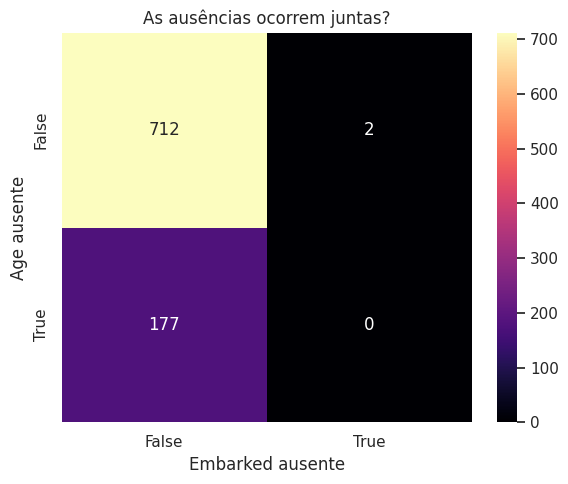

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

MCAR- seria o embarked com apenas 2 faltantes trata-se de uma falha puramente aleatória
MAR - A ausência da idade não é puramente aleatória, pois está correlacionada com a classe do bilhete
MNAR - A omissão da cabine está diretamente ligada ao fato do passageiro pertencer às classes mais baixas (3ª classe)

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:

VARS_QUANT = ["Age", "Fare", "SibSp", "Parch"]
VARS_QUALI = ["Pclass", "Sex", "Embarked", "sobreviveu"]


desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()


(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Age,29.70,28.00,14.53,0.42,80.00,0.39,0.18
Fare,32.20,14.45,49.69,0.00,512.33,4.79,33.40
SibSp,0.52,0.00,1.10,0.00,8.00,3.70,17.88
Parch,0.38,0.00,0.81,0.00,6.00,2.75,9.78


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?
Resposta- A maioria das pessoas no Titanic viajou de 2ª ou 3ª classe pagando passagens baratas, enquanto só uma minoria da 1ª classe pagou tarifas altas por cabines de luxo. Além disso, grande parte dos passageiros era de adultos jovens viajando sozinhos ou com poucos parentes. É por isso que os dados de Fare, SibSp e Parch ficam concentrados perto do zero, formando aquela cauda longa para a direita por causa desses poucos valores muito fora do padrão.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


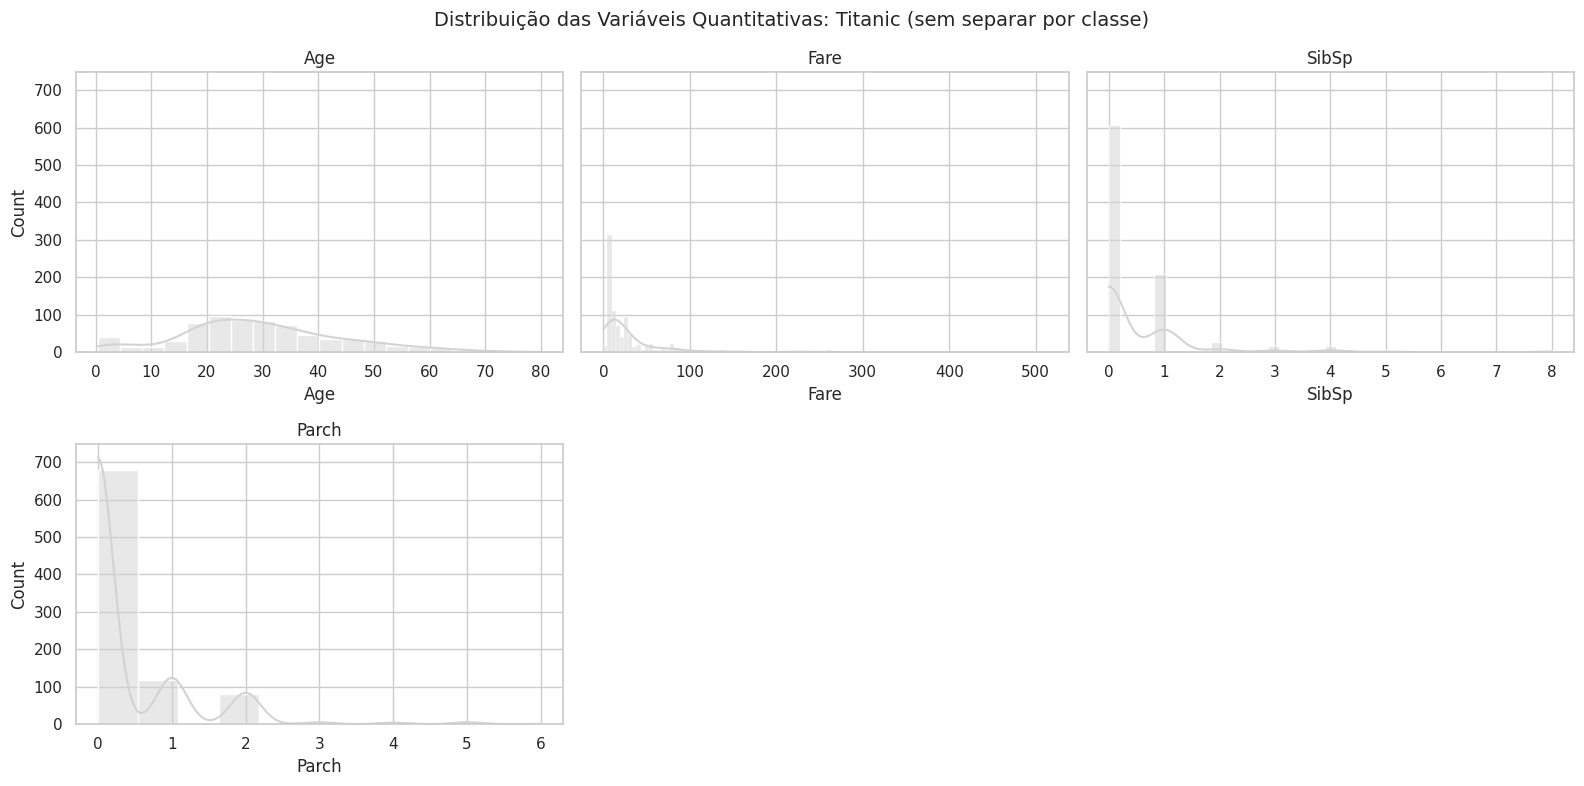

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Titanic (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

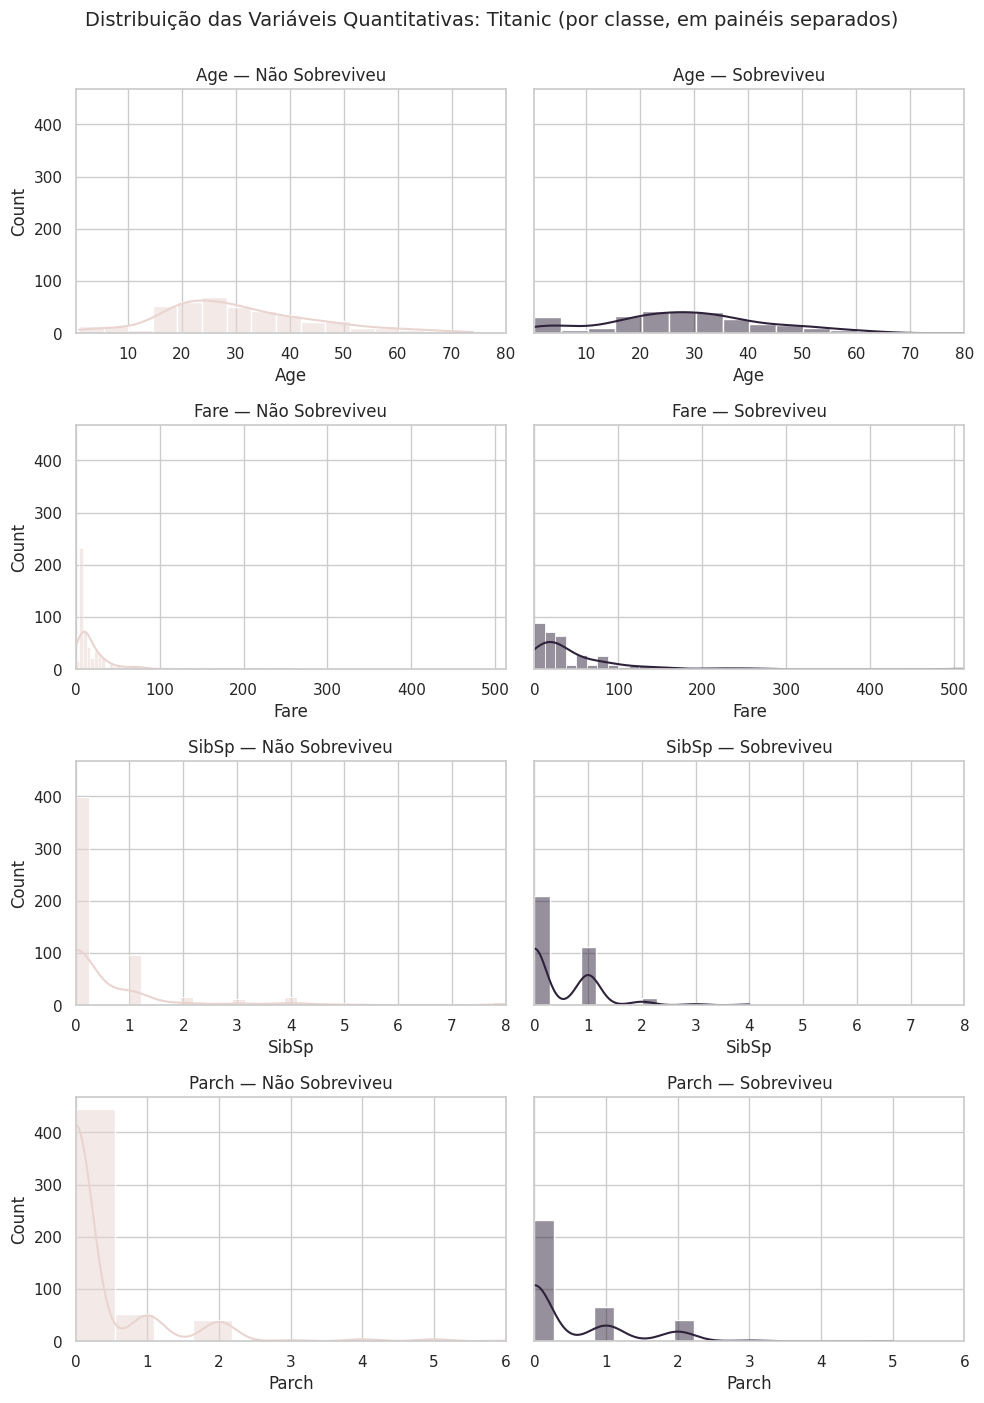

In [ ]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Não Sobreviveu", COR_CONTEXTO), ("Sobreviveu", COR_DESTAQUE)]):
        subset = df[df["sobreviveu"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Titanic (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?

Analisando os painéis, as diferenças mais claras estão nas variáveis Fare e Age: enquanto no grupo que não sobreviveu as tarifas (Fare) ficam praticamente todas esmagadas perto de zero e a idade (Age) se concentra fortemente entre jovens de 20 e 30 anos, no grupo dos sobreviventes a distribuição das tarifas é bem mais espalhada para a direita (valores mais altos) e surge um pico evidente de crianças de 0 a 10 anos. Já para SibSp e Parch, a maioria em ambos os grupos viajava sozinha (valor 0), mas quem não sobreviveu apresenta uma concentração ainda maior nesse ponto e uma queda muito mais brusca

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

Shapiro-Wilk — Age: estatística=0.9815, p-valor=7.337e-08
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


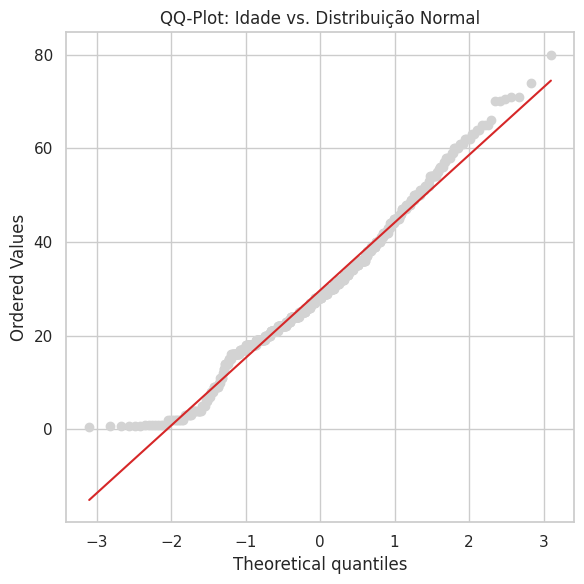

In [ ]:

stat_sw, p_valor_sw = stats.shapiro(df["Age"].dropna())
print(f"Shapiro-Wilk — Age: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — Idade"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["Age"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Idade vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Age,0.9815,0.0,True
Fare,0.5219,0.0,True
SibSp,0.5130,0.0,True
Parch,0.5328,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

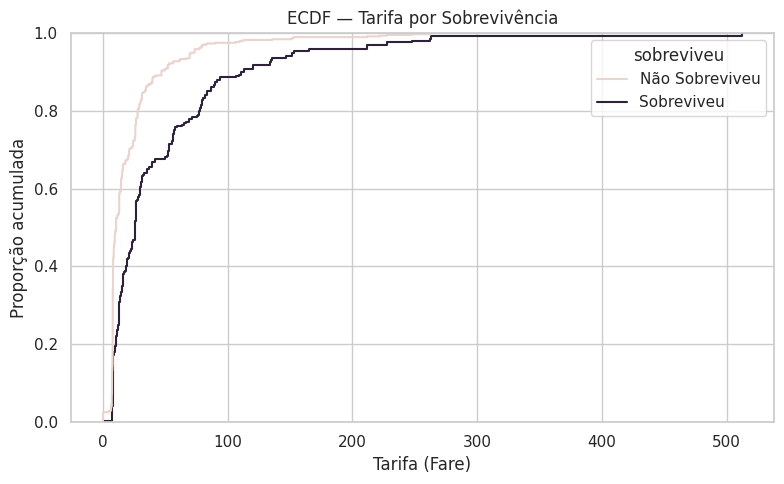

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="Fare", hue="sobreviveu",
             palette={"Não Sobreviveu": COR_CONTEXTO, "Sobreviveu": COR_DESTAQUE})
plt.title("ECDF — Tarifa por Sobrevivência")
plt.xlabel("Tarifa (Fare)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

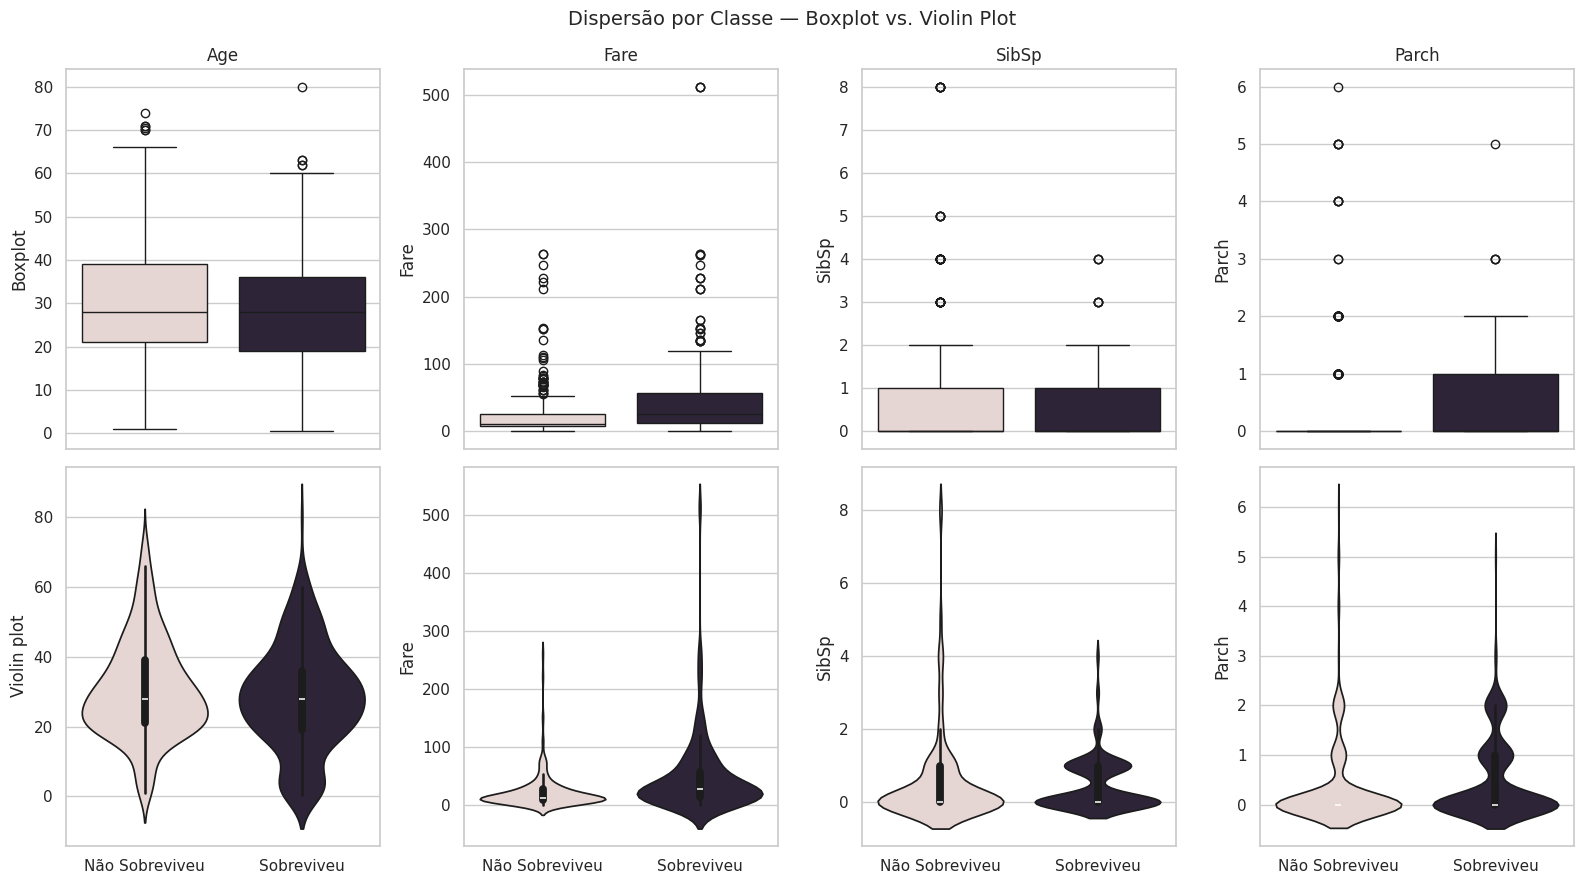

In [ ]:
media_fare = df["Fare"].mean()
mediana_fare = df["Fare"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Fare", kde=True, color=COR_NEUTRA)
plt.axvline(media_fare, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_fare:.1f}")
plt.axvline(mediana_fare, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_fare:.1f}")
plt.title("Tarifa (Fare): Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

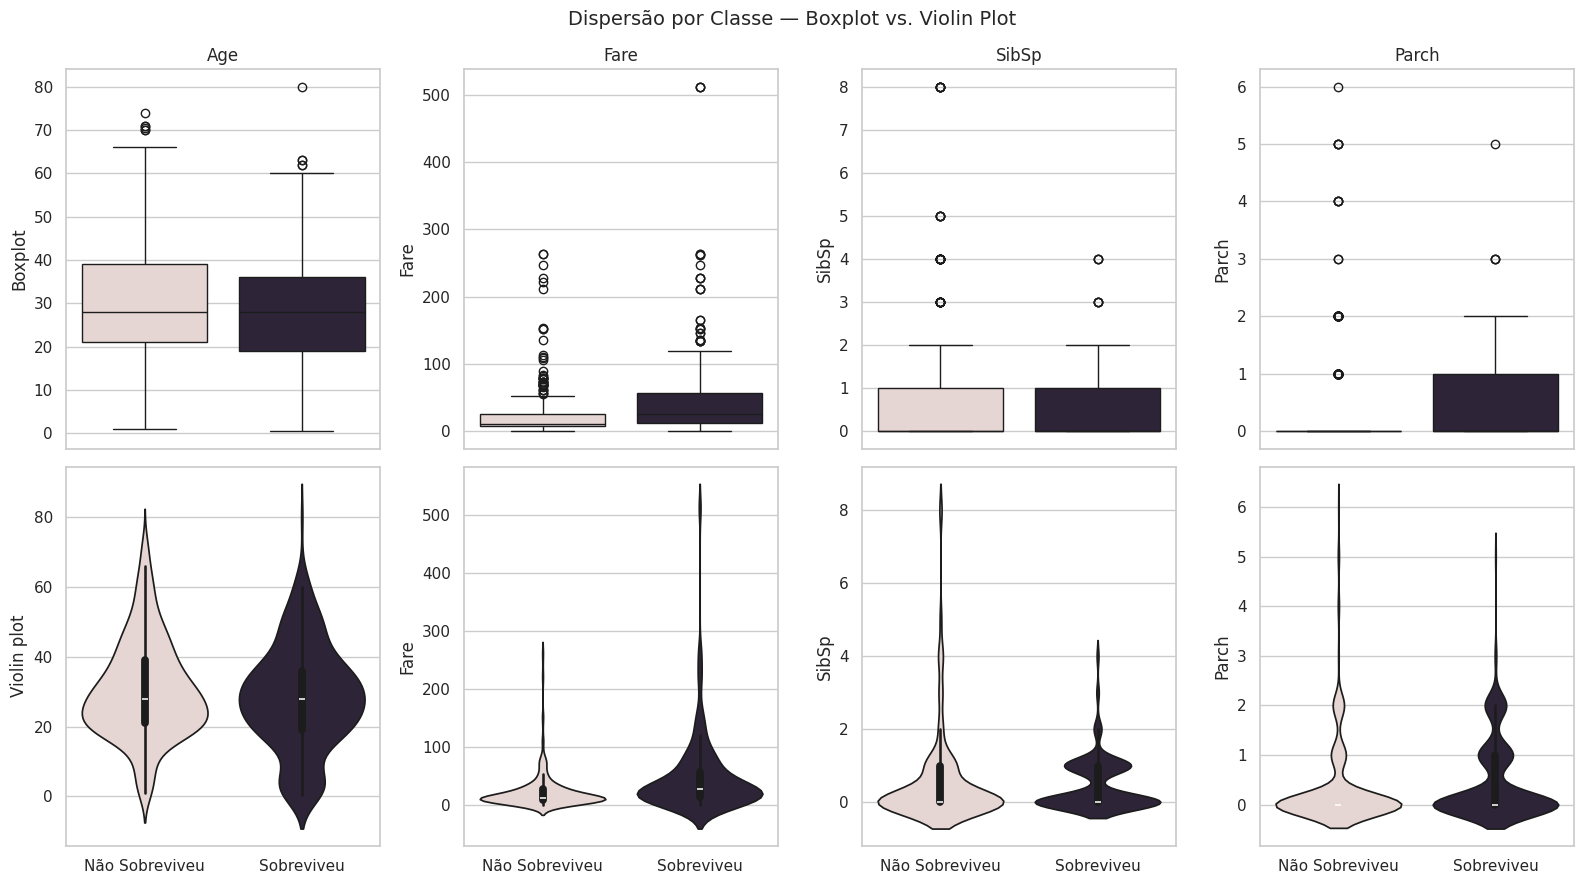

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Não Sobreviveu": COR_CONTEXTO, "Sobreviveu": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="sobreviveu", y=col, hue="sobreviveu",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="sobreviveu", y=col, hue="sobreviveu",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.Resposta - Sim, a variável Fare é a que apresenta a diferença mais nítida, com a caixa (IQR) do grupo de sobreviventes posicionada bem mais ao alto em relação aos não sobreviventes, cujos valores ficam quase todos esmagados perto do zero. Além disso, no gráfico de Parch, a caixa dos não sobreviventes é totalmente achatada em zero, enquanto a dos sobreviventes se expande até o valor 1. No caso de Age, embora os quartis sejam parecidos, o violin plot revela um alargamento na base entre os sobreviventes por conta da presença de crianças, indicando que essas três variáveis serão determinantes para diferenciar os dois grupos.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
Age,-6.69,64.81,11.0
Fare,-26.72,65.63,116.0
SibSp,-1.50,2.50,46.0
Parch,0.00,0.00,213.0


### Visualizando os Outliers

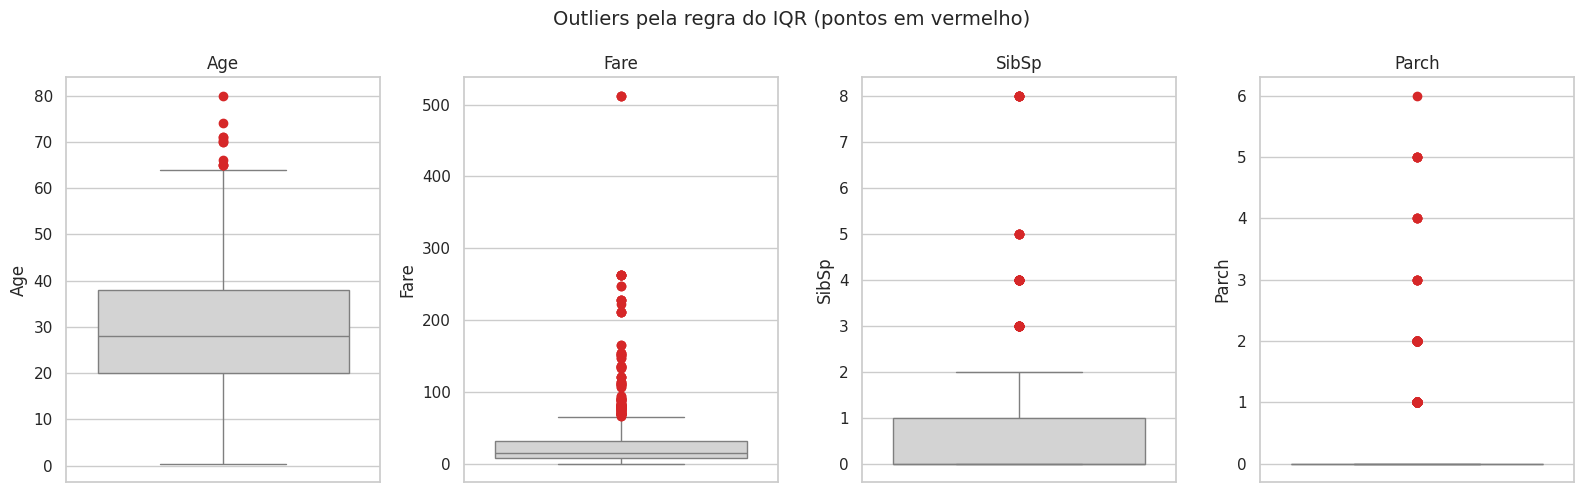

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

# **Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover. resposta- Olhando os dados do Titanic (especialmente Fare, Age, SibSp e Parch), todos esses outliers se encaixam na categoria de Outliers Estatísticos (Legítimos). Eles não violam regras de negócio nem são erros de digitação: faz sentido histórico existir passageiros idosos de até 80 anos (Age), famílias grandes com até 8 irmãos/cônjuges (SibSp) ou passagens caríssimas de 512 libras (Fare) para as suítes de luxo. Como são dados reais e válidos do contexto socioeconômico do navio, a orientação é manter essas observações ou aplicar transformações (como log em Fare) para amenizar o impacto da assimetria nos modelos, evitando a remoção.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()


df = df.dropna(subset=["Embarked"]).reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 891 | Linhas depois: 889 | Removidas: 2


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

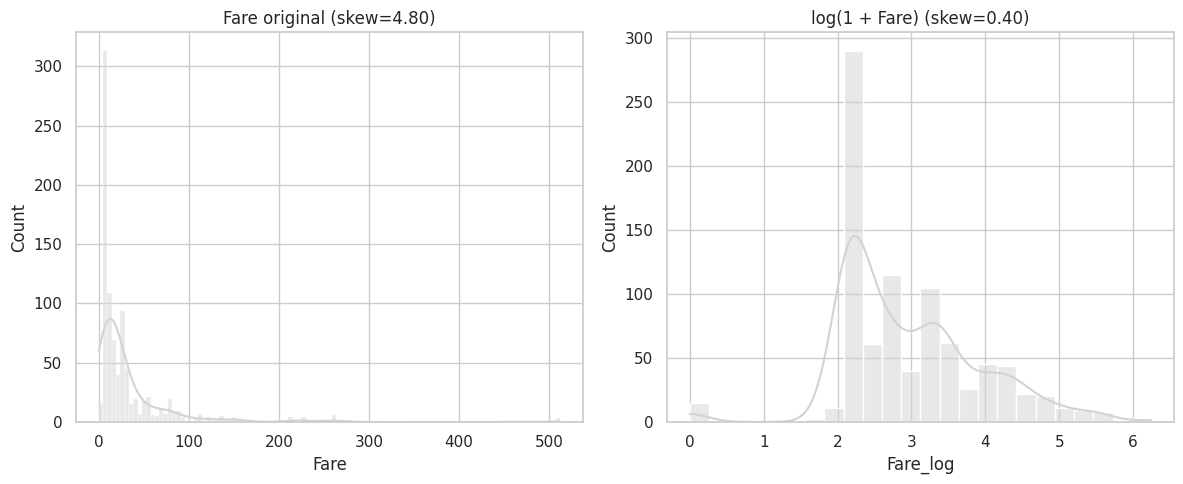

In [ ]:
df["Fare_log"] = np.log1p(df["Fare"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="Fare", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Fare original (skew={df['Fare'].skew():.2f})")

sns.histplot(data=df, x="Fare_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Fare) (skew={df['Fare_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

Sim, a transformação logarítmica reduziu drasticamente a assimetria da variável Fare, fazendo a métrica de skewness despencar de $4.80$ (uma assimetria positiva altíssima) para apenas $0.40$ (praticamente uma distribuição simétrica). O gráfico transformado mostra claramente uma curva em formato de sino muito mais aproximada da distribuição normal, comprimindo a cauda longa dos valores altos de passagens e aproximando a distribuição para uso em futuros modelos sensíveis à escala ou testes paramétricos.


## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Age,29.64,28.00,14.49,0.42,80.00,0.39,0.19
Fare,32.10,14.45,49.70,0.00,512.33,4.80,33.51
SibSp,0.52,0.00,1.10,0.00,8.00,3.69,17.84
Parch,0.38,0.00,0.81,0.00,6.00,2.75,9.75


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Age,0.389,0.389,0.178,0.188,-0.000,0.010
Fare,4.787,4.801,33.398,33.508,0.014,0.110
SibSp,3.695,3.691,17.880,17.839,-0.004,-0.041
Parch,2.749,2.745,9.778,9.751,-0.004,-0.028


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

Não, os valores praticamente não mudaram, e isso era o esperado. Como foram removidas apenas 2 linhas da coluna Embarked (menos de 0,3% do dataset) e nenhum outlier foi descartado, a estrutura e a variabilidade dos dados originais foram integralmente preservadas. Essa variação mínima nos deltas (praticamente zero) confirma que a limpeza foi conservadora e segura, eliminando apenas o ruído necessário de valores nulos sem distorcer as distribuições reais da população do Titanic.

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["Age"].dropna())
print(f"Shapiro-Wilk (antes)  — Age: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — Age: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — Age: estatística=0.9815, p-valor=7.337e-08
Shapiro-Wilk (depois) — Age: estatística=0.9815, p-valor=7.897e-08


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

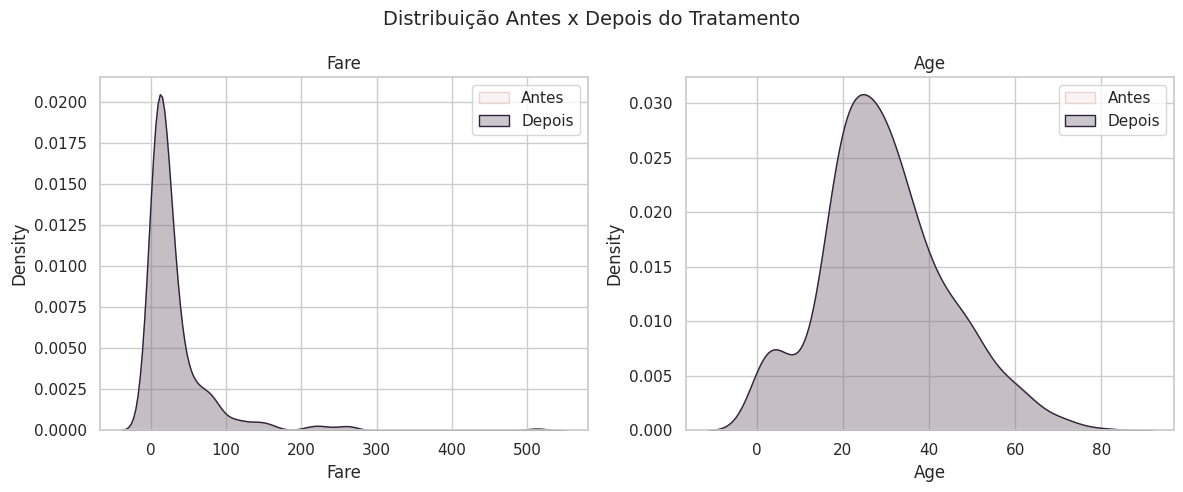

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["Fare", "Age"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

Sim, as curvas de densidade do gráfico se sobrepõem com perfeição, e a variável Age continua rejeitando a hipótese de normalidade pelo teste de Shapiro-Wilk (p-valor bem menor que 0.05 antes e depois). Isso era exatamente o esperado, pois a remoção pontual de apenas duas linhas com dados faltantes em Embarked não impactou a forma das distribuições quantitativas nem distorceu os dados originais. Essa verificação confirma visualmente e estatisticamente que a estratégia de limpeza garantiu a integridade do dataset

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- Pclass ---
        absoluta  relativa
Pclass                    
3            491     0.552
1            214     0.241
2            184     0.207
\n--- Sex ---
        absoluta  relativa
Sex                       
male         577     0.649
female       312     0.351
\n--- Embarked ---
          absoluta  relativa
Embarked                    
S              644     0.724
C              168     0.189
Q               77     0.087
\n--- sobreviveu ---
                absoluta  relativa
sobreviveu                        
Não Sobreviveu       549     0.618
Sobreviveu           340     0.382


#### Visualizando as frequências

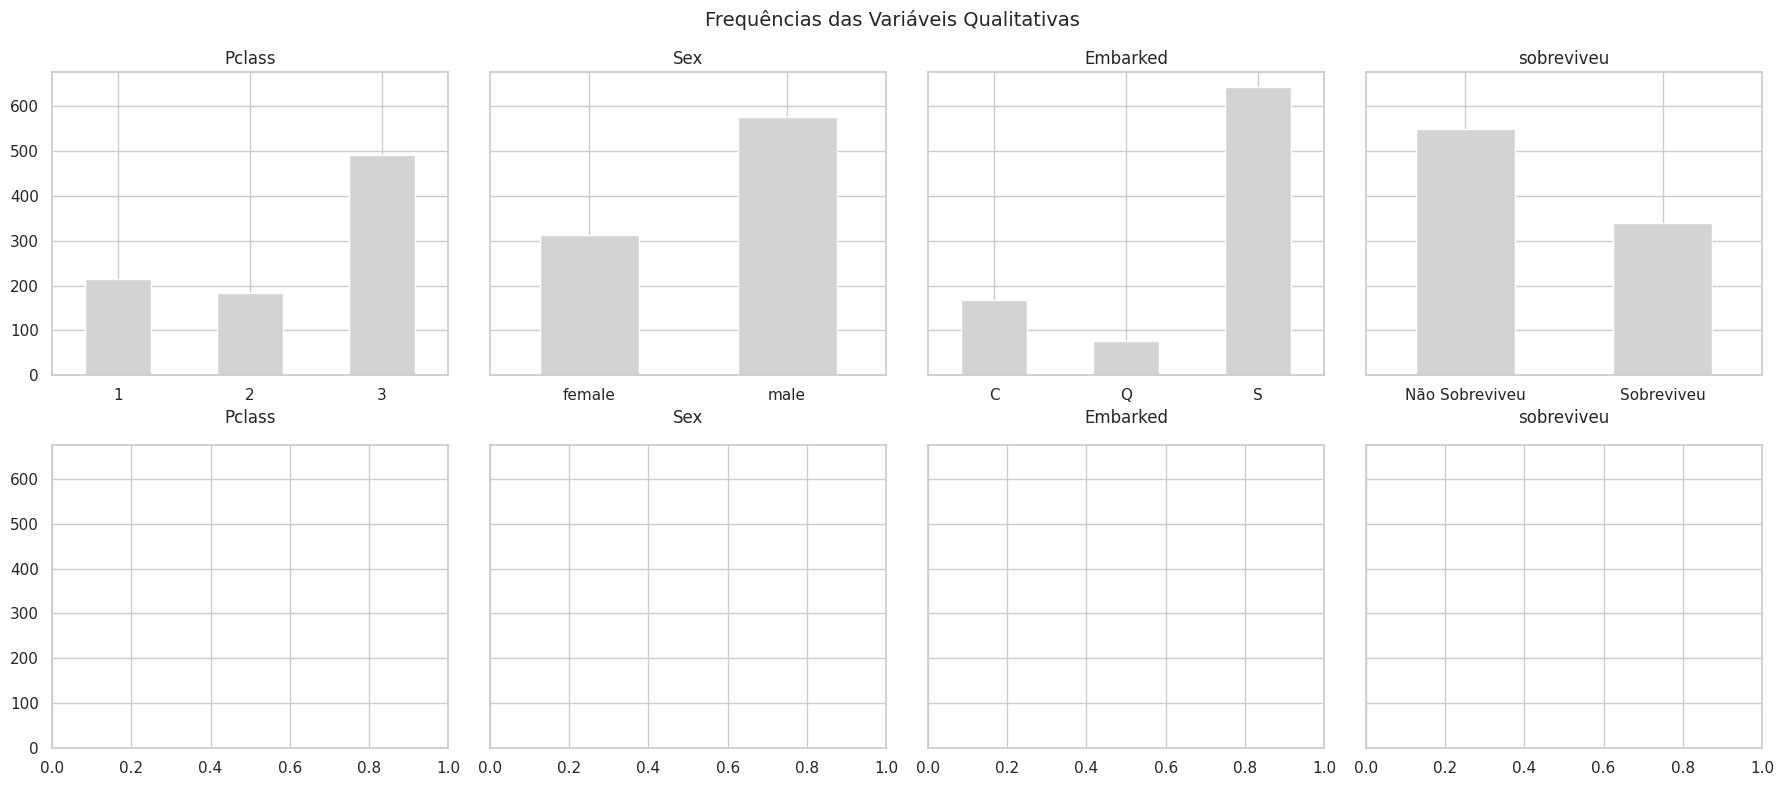

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

Sim, a variável Embarked apresenta o desbalanceamento mais acentuado, com o porto de Southampton Sconcentrando 72,4% dos passageiros, enquanto Queenstown Q representa apenas 8,7%. Além disso, Pclass tem a 3ª classe dominando 55,2% da amostra e Sex possui quase o dobro de homens 64,9 em relação a mulheres 35,1.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })


pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in VARS_QUALI}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Pclass,3.0,2.67,0.907
Sex,2.0,1.85,0.935
Embarked,3.0,8.36,0.692
sobreviveu,2.0,1.61,0.960


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

A variável Embarked é a mais desbalanceada do conjunto, apresentando a menor entropia normalizada 0,692 e a maior razão de desbalanceamento 8,36, devido à forte predominância do porto de Southampton. Em contrapartida, a variável alvo sobreviveu apresenta uma entropia alta 0,960 e uma razão de apenas 1,61, o que indica um bom balanceamento entre as classes

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

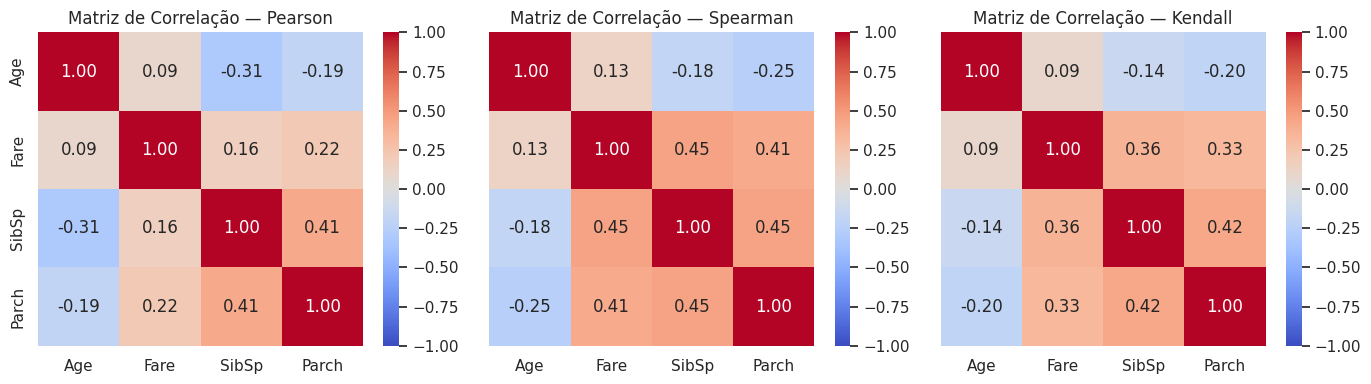

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

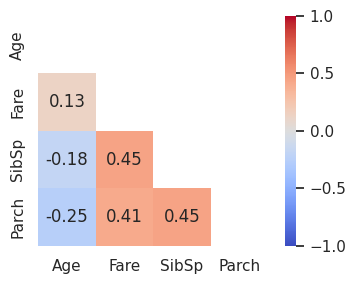

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

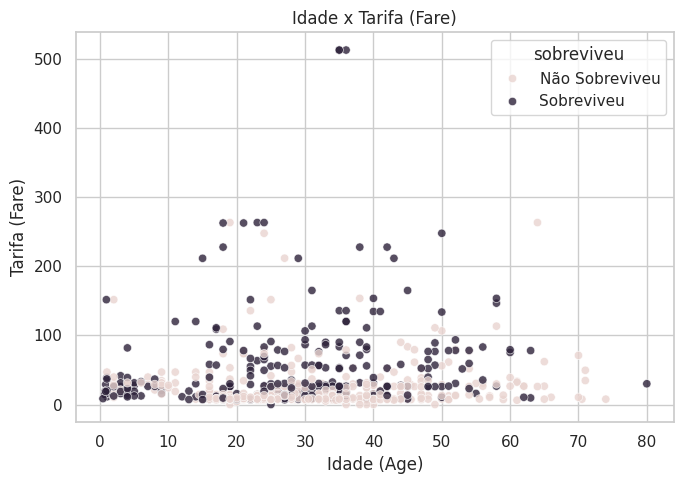

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Age", y="Fare", hue="sobreviveu",
                palette={"Não Sobreviveu": COR_CONTEXTO, "Sobreviveu": COR_DESTAQUE}, alpha=0.8)
plt.title("Idade x Tarifa (Fare)")
plt.xlabel("Idade (Age)")
plt.ylabel("Tarifa (Fare)")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme a idade aumenta, `thalach` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_nao_sobreviveu = df.loc[df["sobreviveu"] == "Não Sobreviveu", col].dropna()
    grupo_sobreviveu = df.loc[df["sobreviveu"] == "Sobreviveu", col].dropna()

    stat_t, p_t = stats.ttest_ind(grupo_nao_sobreviveu, grupo_sobreviveu, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_nao_sobreviveu, grupo_sobreviveu)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
Age,0.02931,0.12837,False
Fare,0.00000,0.00000,True
SibSp,0.25002,0.00673,False
Parch,0.01188,0.00003,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`cp` (tipo de dor no peito) tem 4 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

ANOVA          — Fare entre categorias de Pclass: estatística=240.388, p-valor=3.9731e-84
Kruskal-Wallis — Fare entre categorias de Pclass: estatística=434.708, p-valor=4.0204e-95


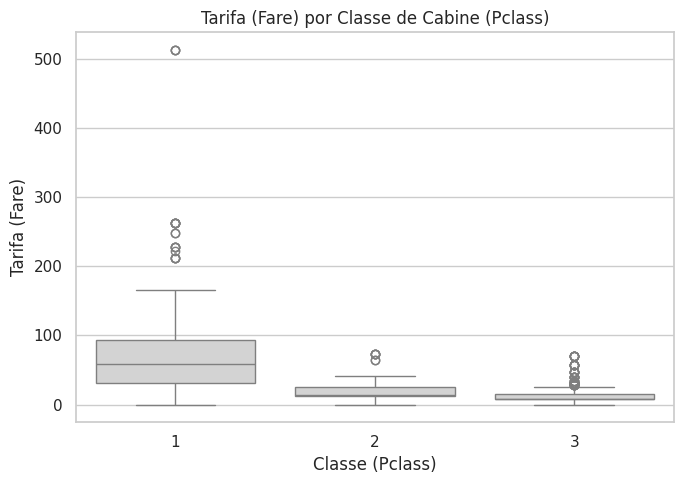

In [ ]:
grupos_pclass = [grupo["Fare"].dropna().values for _, grupo in df.groupby("Pclass")]

stat_anova, p_anova = stats.f_oneway(*grupos_pclass)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_pclass)          # não-paramétrico

print(f"ANOVA          — Fare entre categorias de Pclass: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — Fare entre categorias de Pclass: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Pclass", y="Fare", color=COR_NEUTRA)
plt.title("Tarifa (Fare) por Classe de Cabine (Pclass)")
plt.xlabel("Classe (Pclass)")
plt.ylabel("Tarifa (Fare)")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `cp`? Como já sabemos que `thalach` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

#### Qualitativa x Qualitativa

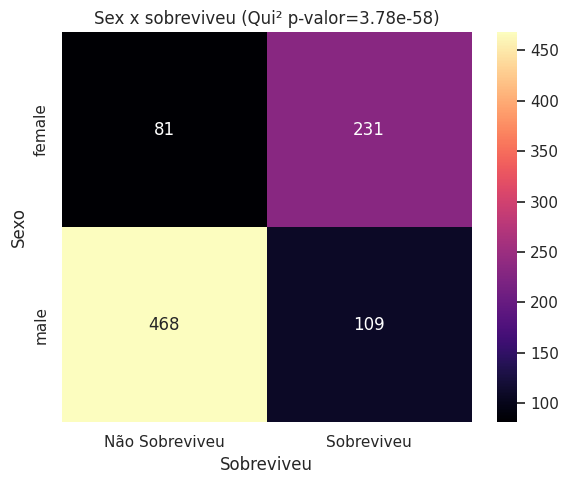

In [ ]:
contingencia_sex = pd.crosstab(df["Sex"], df["sobreviveu"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_sex)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_sex, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Sex x sobreviveu (Qui² p-valor={p_chi2:.4g})")
ax.set_xlabel("Sobreviveu")
ax.set_ylabel("Sexo")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

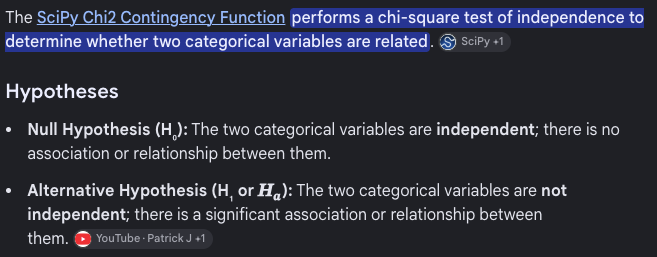

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [ ]:

df["sexo_label"] = df["Sex"].map({"female": "Feminino", "male": "Masculino"})


df["faixa_etaria"] = pd.cut(df["Age"], bins=[0, 12, 18, 60, 100],
                             labels=["Criança (<12)", "Jovem (12-17)", "Adulto (18-59)", "Idoso (60+)"])

print("Desbalanceamento — sexo:")
print(metrica_desbalanceamento(df["sexo_label"]))
print("\nDesbalanceamento — faixa etária:")
print(metrica_desbalanceamento(df["faixa_etaria"]))

Desbalanceamento — sexo:
n_classes                 2.000
razao_desbalanceamento    1.850
entropia_normalizada      0.935
dtype: float64

Desbalanceamento — faixa etária:
n_classes                  4.000
razao_desbalanceamento    26.290
entropia_normalizada       0.545
dtype: float64


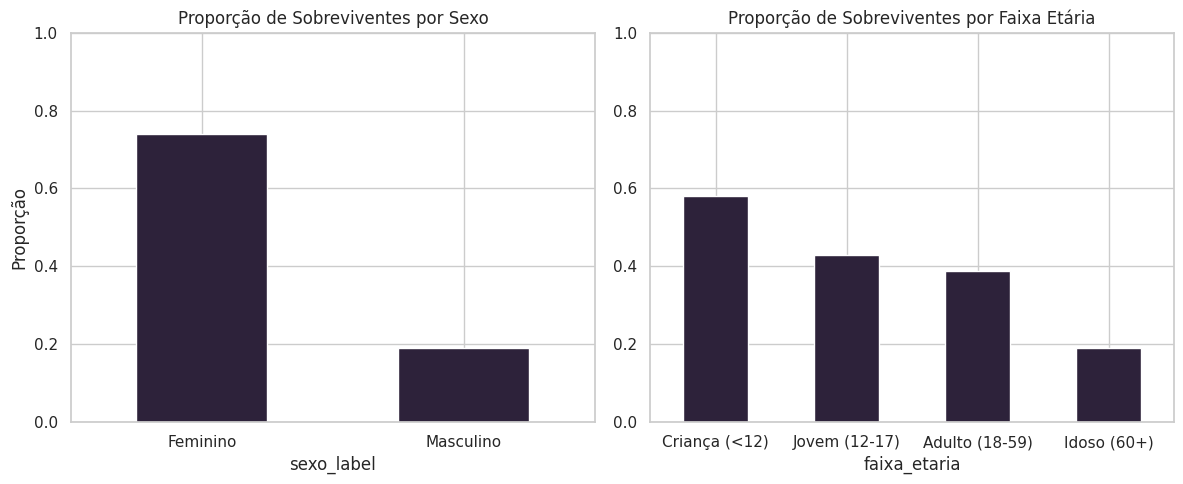

In [ ]:
prop_por_sexo = pd.crosstab(df["sexo_label"], df["sobreviveu"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_etaria"], df["sobreviveu"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_sexo["Sobreviveu"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção de Sobreviventes por Sexo")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa["Sobreviveu"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção de Sobreviventes por Faixa Etária")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão clínico real e bem documentado (ex: risco cardíaco cresce com a idade), ou pode ser um artefato de **quem** foi encaminhado para o exame nesses hospitais específicos? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

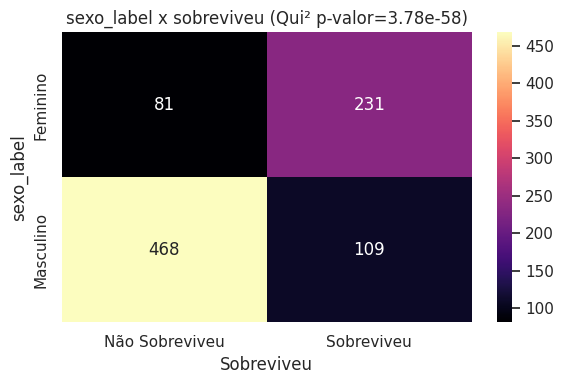

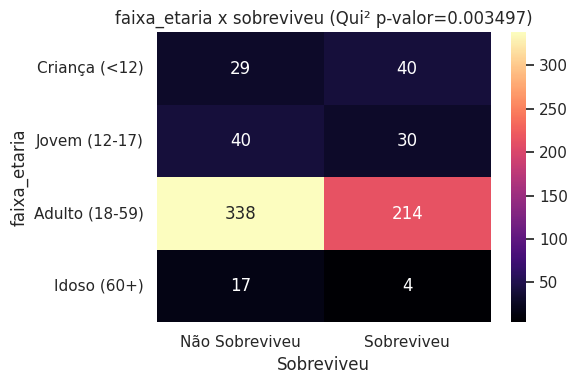

In [ ]:
for atributo in ["sexo_label", "faixa_etaria"]:
    contingencia = pd.crosstab(df[atributo], df["sobreviveu"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x sobreviveu (Qui² p-valor={p_valor:.4g})")
    ax.set_xlabel("Sobreviveu")
    ax.set_ylabel(atributo)
    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

#### Outliers bivariados

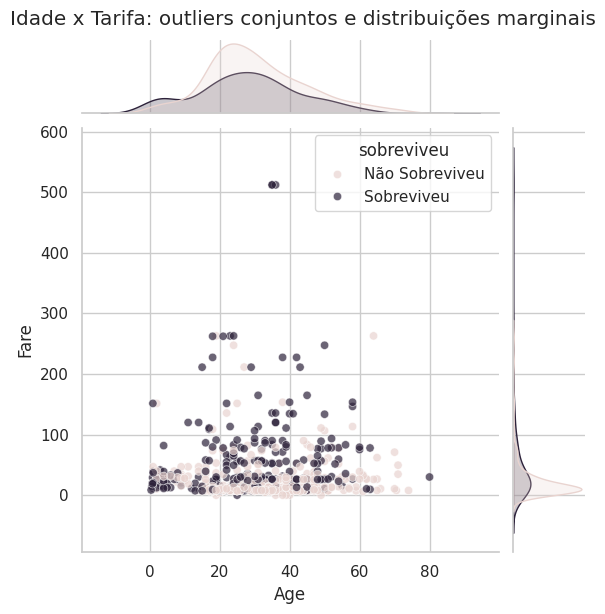

In [ ]:
sns.jointplot(data=df, x="Age", y="Fare", hue="sobreviveu",
              palette={"Não Sobreviveu": COR_CONTEXTO, "Sobreviveu": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Idade x Tarifa: outliers conjuntos e distribuições marginais", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`?

#### Análise Multivariada

##### Matriz de Correlação

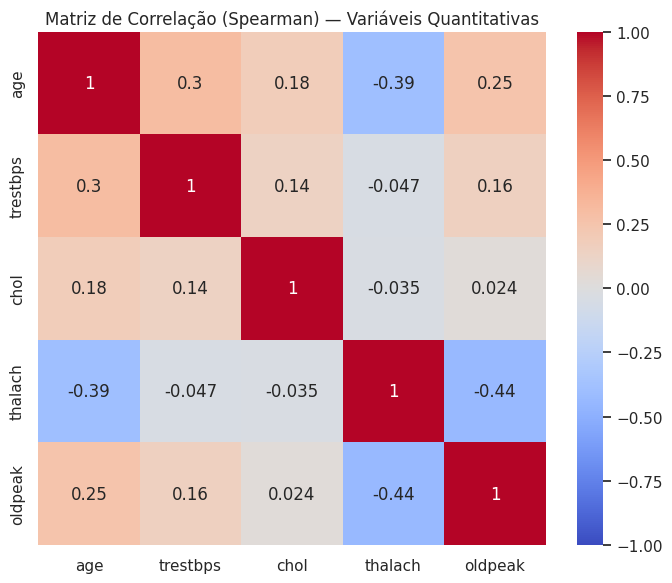

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

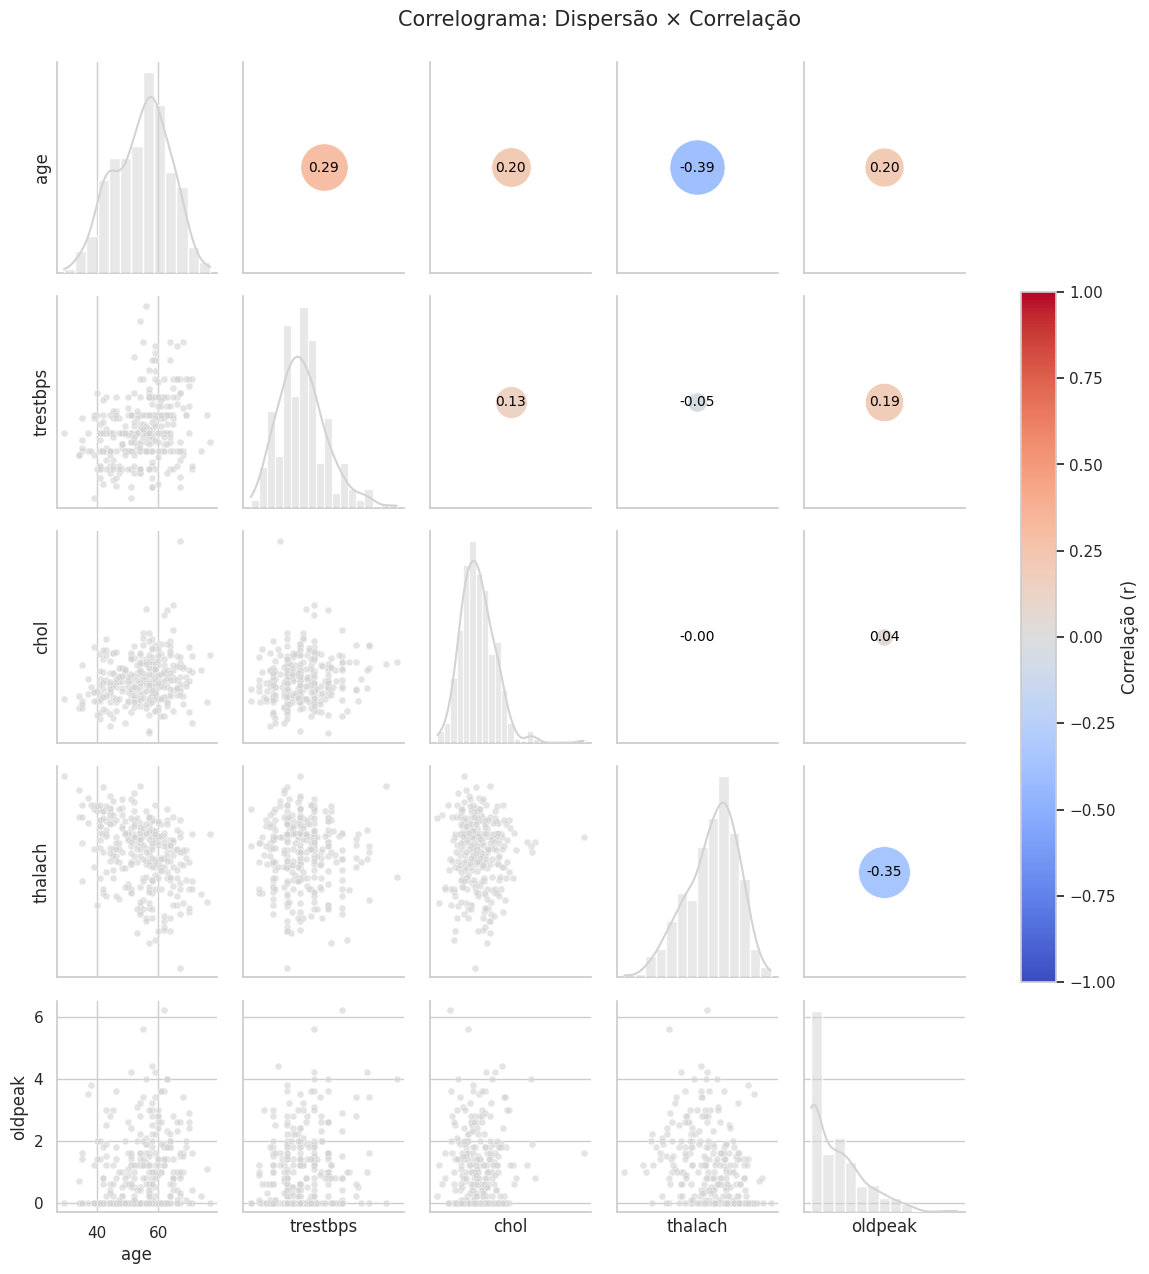

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


In [ ]:
from pathlib import Path


raiz = Path.cwd()

if not (raiz / "app.py").exists() and (raiz.parent / "app.py").exists():
    raiz = raiz.parent


saida = raiz / "data" / "clean" / "titanic_clean.csv"
saida.parent.mkdir(parents=True, exist_ok=True)


df.to_csv(saida, index=False)

print(f"Arquivo salvo em: {saida.resolve()}")

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




Utilizei a i.a para adaptação do código no meu contexto e em alguns momentos de difculdade para interpretar os resultados gerados, bem como para formular melhor as respostas para torna-las mais coerentes